# Homework 8: Practicing with Geopandas

## Part 1: Mapping Evictions

Please complete the eviction mapping exercise that we started in class. Remember that you're creating a choropleth map of evictions in NYC in 2024.

In [1]:
import geopandas as gpd
import pandas as pd

Remember the magic command for every notebook

In [2]:
%matplotlib inline

Load up the unemployment data

In [3]:
evictions = pd.read_csv("data/Evictions_20240615.csv")


In [4]:
# I'm copy and pasting this from class:

In [5]:
# Okay, now I have to aggregate the data for postal code. 

evictions_by_zipcode = evictions["Eviction Postcode"].value_counts().reset_index()

In [6]:
evictions_by_zipcode["zip_str"] = evictions_by_zipcode["Eviction Postcode"].astype(str)
evictions_by_zipcode

,Eviction Postcode,count,zip_str
0,10467,2509,10467
1,10458,2449,10458
2,10456,2209,10456
3,10453,2183,10453
4,11226,1978,11226
...,...,...,...
237,10423,1,10423
238,10123,1,10123
239,11240,1,11240
240,11266,1,11266


In [7]:
zipcode = gpd.read_file("data/nyc-zip-code-tabulation-areas-polygons.geojson")

#Reprojection

zipcode = zipcode.to_crs(epsg=5070)

zipcode.dtypes

OBJECTID             int32
postalCode             str
PO_NAME                str
STATE                  str
borough                str
ST_FIPS                str
CTY_FIPS               str
BLDGpostalCode       int32
Shape_Leng         float64
Shape_Area         float64
@id                    str
geometry          geometry
dtype: object

In [8]:
# Merge this hoe

evictions_geo = zipcode.merge(
    evictions_by_zipcode,
    left_on = "postalCode",
    right_on = "zip_str"
)

evictions_geo

,OBJECTID,postalCode,PO_NAME,STATE,borough,ST_FIPS,CTY_FIPS,BLDGpostalCode,Shape_Leng,Shape_Area,@id,geometry,Eviction Postcode,count,zip_str
0,1,11372,Jackson Heights,NY,Queens,36,081,0,20624.692317,2.016328e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1836499.921 2185706.705, 1834479.637...",11372,555,11372
1,2,11004,Glen Oaks,NY,Queens,36,081,0,23002.816039,2.260653e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1849408.446 2188881.404, 1849603.879...",11004,24,11004
2,3,11040,New Hyde Park,NY,Queens,36,081,0,15749.161511,6.269333e+06,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1850488.732 2187856.272, 1850170.165...",11040,13,11040
3,4,11426,Bellerose,NY,Queens,36,081,0,35932.810639,4.941836e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1848333.318 2189049.857, 1848359.226...",11426,64,11426
4,5,11365,Fresh Meadows,NY,Queens,36,081,0,38693.565676,6.938587e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1841838.927 2184443.991, 1841787.547...",11365,308,11365
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
207,258,10065,New York,NY,Manhattan,36,061,0,15541.743364,1.144258e+07,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1829348.449 2185784.277, 1829237.952...",10065,186,10065
208,259,10075,New York,NY,Manhattan,36,061,0,13540.765334,4.809655e+06,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1829516.106 2186254.794, 1829384.034...",10075,101,10075
209,260,10069,New York,NY,Manhattan,36,061,0,7780.632133,2.372366e+06,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1825995.43 2186912.754, 1826131.249 ...",10069,20,10069
210,261,10281,New York,NY,Manhattan,36,061,0,4717.025266,9.580872e+05,http://nyc.pediacities.com/Resource/PostalCode...,"POLYGON ((1825672.968 2178617.816, 1825527.265...",10281,1,10281


Text(0.5, 1.0, 'Evictions by Zip Code')

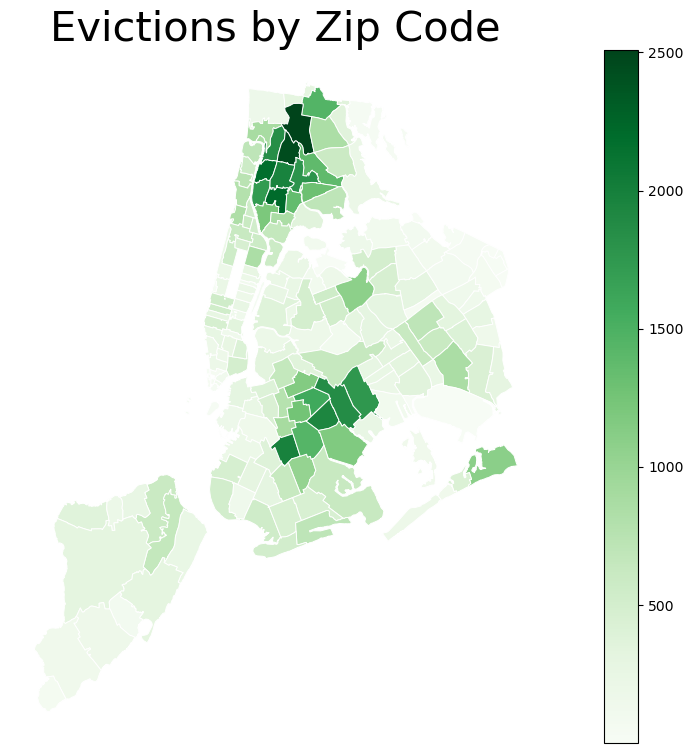

In [9]:
ax = evictions_geo.plot(
    column = "count",
    legend = True,
    cmap = "Greens",
    edgecolor = "white",
    linewidth = 0.7,
    figsize = (16,9)
)

ax.axis("off")

ax.set_title(
    "Evictions by Zip Code",
    fontsize = 30)


## Part 2: Mapping Unemployment

In the data folder for geopandas, you'll find a file called unemployment_2018. Map the unemployment across counties on the continental U.S. using this dataset. Save the final map as a PNG.

In [10]:
# YOUR CODE HERE

# First, I'm going to read in my unemployment data.

ue_df = pd.read_csv("data/unemployment_2018.csv")
ue_df.dtypes

# Ok, I don't need to aggregate this data because it's not individual instance data. I can now load in my counties. 

state_fips            float64
county_fips           float64
combined_fips         float64
name                      str
percent_unemployed    float64
dtype: object

<Axes: >

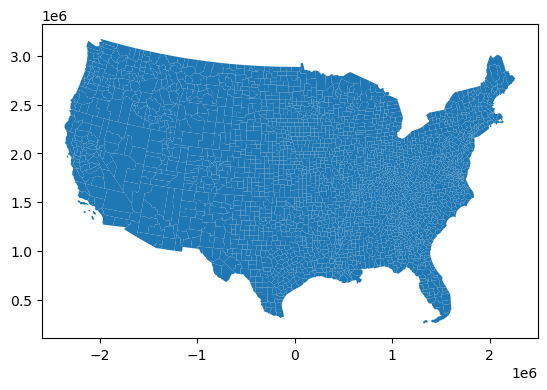

In [11]:
counties = gpd.read_file("data/counties.geojson")
# Ok first I have to exclude the non-continental US fips codes. (Hopefully, I won't have to do it for the unemployment data).
# Their fips codes are: 60, 66, 69, 72, 78, 02, 15

# I'm going to check and see how many of these fips are actually includes (there are 56 codes)

counties["STATEFP"].unique()

# Ok now I'm going to create a reduced df

counties = counties[
    ~counties["STATEFP"].isin(["60", "66", "69", "72", "78", "02", "15"])
    ]

# Ok, that's all set. Let me reproject while I'm here.

counties = counties.to_crs(epsg=5070)

counties.plot()

In [12]:
# Ok, now I need to match up the unemployment and counties data. 

# I'm going to make a combined fips code for the counties and turn it into a float.

counties["combined_fips"] = counties["STATEFP"] + counties["COUNTYFP"]

counties["combined_fips"] = counties["combined_fips"].astype(float)

counties.dtypes

STATEFP               str
COUNTYFP              str
COUNTYNS              str
GEOID                 str
GEOIDFQ               str
NAME                  str
NAMELSAD              str
LSAD                  str
CLASSFP               str
MTFCC                 str
CSAFP                 str
CBSAFP                str
METDIVFP              str
FUNCSTAT              str
ALAND               int64
AWATER              int64
INTPTLAT              str
INTPTLON              str
geometry         geometry
combined_fips     float64
dtype: object

In [13]:
# Ok merging time! #Scared

unemployment_county = counties.merge(
    ue_df,
    left_on = "combined_fips",
    right_on = "combined_fips"
)

unemployment_county

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,...,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,combined_fips,state_fips,county_fips,name,percent_unemployed
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,...,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((1465134.065 731674.673, 1465183.417 ...",12009.0,12.0,9.0,"Brevard County, FL",3.5
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,...,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-2226513.624 2027956.145, -2226521.0...",6055.0,6.0,55.0,"Napa County, CA",2.9
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,...,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((904578.578 1914035.16, 904527.123 19...",18065.0,18.0,65.0,"Henry County, IN",3.5
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,...,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-1143964.058 1088757.697, -1143903.6...",35029.0,35.0,29.0,"Luna County, NM",11.9
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,...,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((1754791.667 1994124.857, 1755150.913...",10001.0,10.0,1.0,"Kent County, DE",4.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3095,56,015,01605073,56015,0500000US56015,Goshen,Goshen County,06,H1,G4020,...,5764310957,16969719,+42.0894553,-104.3535403,"POLYGON ((-704884.236 2211185.76, -704487.032 ...",56015.0,56.0,15.0,"Goshen County, WY",3.3
3096,55,107,01581114,55107,0500000US55107,Rusk,Rusk County,06,H1,G4020,...,2365981756,44924199,+45.4727342,-091.1367443,"POLYGON ((387998.453 2488313.527, 387982.554 2...",55107.0,55.0,107.0,"Rusk County, WI",4.0
3097,21,079,00516886,21079,0500000US21079,Garrard,Garrard County,06,H1,G4020,...,595502296,10414783,+37.6301619,-084.5458557,"POLYGON ((980415.031 1689073.563, 980445.072 1...",21079.0,21.0,79.0,"Garrard County, KY",4.4
3098,19,177,00465277,19177,0500000US19177,Van Buren,Van Buren County,06,H1,G4020,...,1255605672,14880500,+40.7541168,-091.9529430,"POLYGON ((319198.812 1994179.49, 319368.793 19...",19177.0,19.0,177.0,"Van Buren County, IA",2.7


Text(0.5, 1.0, 'Unemployment by County')

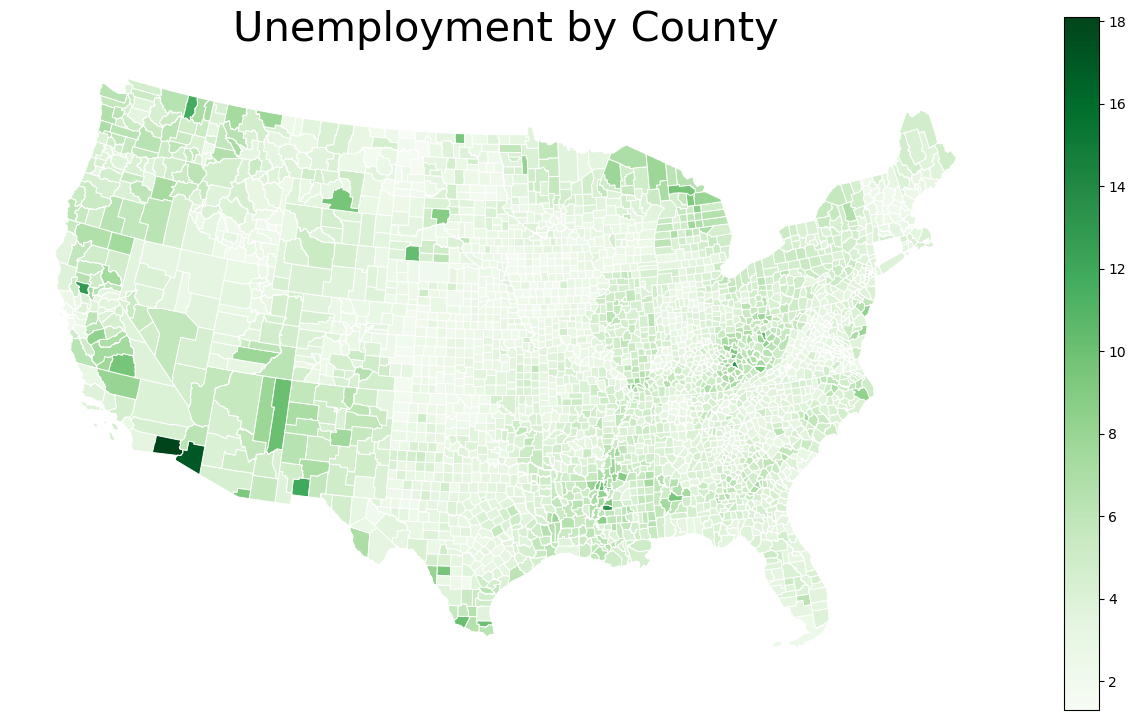

In [14]:
# Ok time to PLOT.

ax = unemployment_county.plot(
    column = "percent_unemployed",
    legend = True,
    cmap = "Greens",
    edgecolor = "white",
    linewidth = 0.7,
    figsize = (16,9)
)

ax.axis("off")

ax.set_title(
    "Unemployment by County",
    fontsize = 30)


## Part 3: Reading

To continue our conversation on problematic investigations, let's read this piece from CJR. It doesn't have anything to do with data, per se, but it brings up questions around the ethics of collecting, analyzing, and visualizing data about vulnerable populations. 

https://www.cjr.org/feature/figueroa-street-ethical-duty-care-sex-trafficking-responsible-reporting-new-york-times-nyt-magazine-emily-baumgaertner-nunn.php 

Answer: What are your thoughts on the controversy? What could the Times have done differently to assuague the advocates' concerns? 

(At least 150 words please!)



Thoughts:

My first immediate thought upon starting this article — which I felt vindicated in the longer I was reading — was that the investigation was inherently flawed as much of it seemed to have taken place from the viewpoint of an LAPD car. Twenty years ago, this might have been a socially acceptable POV for this reporting, but now, I feel as though it is lazy reporting. The reporter should not have relied largely on one voice to tell the story in the first place (especially when discussing experiences like this one), as it assumes that there is one universal experience had by all victims. Furthermore, this voice was not necessarily allowed to exercise "meaningful consent," has the CJR article details. It's weird that the author attempted to shield her story from criticism on this level on the basis of arbitrary and unrevealed "clinical markers." I am glad to hear that Ana felt that telling her story was an "empowering part of her healing journey," but I think the author could've just left it at that when it came to defending her access to Ana. I believe it would've been better to be more transparent about the reporting process and the process for getting consent from sources, so that, even if the methods were ultimately unethical, the reader has the ability to choose to read the story with that background in mind. 

I think that the Times could have assuaged concerns, also, by changing the way the story was framed. I didn't read the totality of the original story, but from the CJR critique and what I saw, it was largely framed as a police-officer-saves-damsel-in-distress. This type of framing first off, premises authors to avoid questions of consent addressed in the first paragraph, as it posits those victims as a subject that needs to be saved, not as human beings with their own, distinct relationships to their struggles, "rescue-rs," and those perpetrating their struggle (traffickers). Secondly, it allows readers to think that the LAPD can only be doing right by these victims, and that the obvious ethical concerns that come with the police being the main source of the reporter's access to sources don't exist. Finally, in a more existential sense, writing stories that frame women in this way can be twisted to defend the exact people who are causing suffering, or allowing for the circumstances of suffering to occur. This critique reminded me a lot of "Do Muslim Women Really Need Saving?," the essay by Lila Abu-Lughod, which discusses the reality of Western media's framing of the Muslim women of Afghanistan as a contributing factor to the suffering that Afghani women have faced as a direct result of US military intervention in the country. Framing the women and girls of the Blade as subjects whose only chance for getting out of the cycle of human trafficking is through LAPD intervention has the potential to hurt them in the long run. With the LAPD directly related to how their story is told, the agency has full authority to build that story in whatever way makes their agency look best, and to have the permission to conduct further policing of those women and children.